# Project 4 — Uganda Rainfall Pattern and Crop Suitability Analyser

**Data:** NASA POWER daily PRECTOTCORR, 2015–2024. **Locations:** Kampala, Gulu and Mbarara. No synthetic data are used.

Run `python run_analysis.py` first, or `python run_analysis.py --offline` if you have downloaded the three daily files manually.

In [3]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
from run_analysis import analyse
analysis = analyse(offline=True)  # Uses saved NASA files; change to False to use API if missing



REGIONAL SUMMARY (10-year monthly climatology)
  region  mean_annual_mm  mean_monthly_mm       cv wettest driest   peaks season_pattern
Kampala        1489.501       124.125083 0.504211     Nov    Jul Apr,Nov        bimodal
   Gulu        1441.794       120.149500 0.523641     Oct    Feb May,Oct        bimodal
Mbarara        1316.534       109.711167 0.430991     Apr    Jul Apr,Oct        bimodal

 cosine 
          Kampala   Gulu  Mbarara
Kampala    1.000  0.880    0.982
Gulu       0.880  1.000    0.917
Mbarara    0.982  0.917    1.000

 pearson 
          Kampala   Gulu  Mbarara
Kampala    1.000  0.387    0.900
Gulu       0.387  1.000    0.532
Mbarara    0.900  0.532    1.000

 euclidean 
          Kampala     Gulu  Mbarara
Kampala    0.000  230.860  107.559
Gulu     230.860    0.000  186.008
Mbarara  107.559  186.008    0.000

Saved CSV results to D:\MSDS\OOP\Assignment 2 mini project\project4_uganda_rainfall\data\processed
Saved charts to D:\MSDS\OOP\Assignment 2 mini project\proj

## Rainfall statistics and rainy seasons

The 12-month vectors represent the mean January–December pattern across 2015–2024. The annual total is therefore the **mean annual total**, not a single year's observation.

In [4]:
display(analysis['summary'])
for r in analysis['regions'].values():
    print(r.name, 'peak months:', [__import__('src.rainfall',fromlist=['MONTHS']).MONTHS[i] for i in r.rainy_peaks()])

,region,mean_annual_mm,mean_monthly_mm,cv,wettest,driest,peaks,season_pattern
0,Kampala,1489.501,124.125083,0.504211,Nov,Jul,"Apr,Nov",bimodal
1,Gulu,1441.794,120.149500,0.523641,Oct,Feb,"May,Oct",bimodal
2,Mbarara,1316.534,109.711167,0.430991,Apr,Jul,"Apr,Oct",bimodal


Kampala peak months: ['Apr', 'Nov']
Gulu peak months: ['May', 'Oct']
Mbarara peak months: ['Apr', 'Oct']


## Regional similarity: cosine, Pearson and Euclidean

Cosine similarity compares the *shape* of the 12-month patterns; it can be high even when rainfall magnitudes differ. Pearson compares centered co-movement and Euclidean distance measures absolute differences in millimetres.

In [5]:
import pandas as pd
for title, matrix in analysis['matrices'].items():
    print(title)
    display(pd.DataFrame(matrix,index=analysis['names'],columns=analysis['names']).round(3))

cosine


,Kampala,Gulu,Mbarara
Kampala,1.000,0.880,0.982
Gulu,0.880,1.000,0.917
Mbarara,0.982,0.917,1.000


pearson


,Kampala,Gulu,Mbarara
Kampala,1.000,0.387,0.900
Gulu,0.387,1.000,0.532
Mbarara,0.900,0.532,1.000


euclidean


,Kampala,Gulu,Mbarara
Kampala,0.000,230.860,107.559
Gulu,230.860,0.000,186.008
Mbarara,107.559,186.008,0.000


## Crop rules and classification

- Maize 500–600 mm is from Uganda MAAIF; beans 300–500 mm and groundnuts 500–700 mm are FAO indicative crop water needs. 
- The 4/3/4-month durations are model assumptions. 
- Above-reference rainfall **does not prove waterlogging**. 
- Monthly classifications use seasonal bounds divided by growing months only as a simplified classroom comparison. Seasonal totals are preferred.

In [6]:
display(analysis['seasonal'].head(18))
display(analysis['monthly_classification'].head(12))

,region,crop,planting_month,growing_months,rainfall_total_mm,min_reference_mm,max_reference_mm,classification
0,Kampala,Maize,Jan,4,491.302,500,600,Below reference
1,Kampala,Maize,Feb,4,583.233,500,600,Within reference
2,Kampala,Maize,Mar,4,584.848,500,600,Within reference
3,Kampala,Maize,Apr,4,461.117,500,600,Below reference
4,Kampala,Maize,May,4,328.087,500,600,Below reference
5,Kampala,Maize,Jun,4,308.885,500,600,Below reference
6,Kampala,Maize,Jul,4,434.216,500,600,Below reference
7,Kampala,Maize,Aug,4,615.076,500,600,Above reference
8,Kampala,Maize,Sep,4,670.112,500,600,Above reference
9,Kampala,Maize,Oct,4,597.383,500,600,Within reference


,region,month,crop,rainfall_mm,reference_min_mm,reference_max_mm,classification
0,Kampala,1,Maize,60.267,125.0,150.000000,Below reference
1,Kampala,1,Beans,60.267,100.0,166.666667,Below reference
2,Kampala,1,Groundnuts,60.267,125.0,175.000000,Below reference
3,Kampala,2,Maize,68.073,125.0,150.000000,Below reference
4,Kampala,2,Beans,68.073,100.0,166.666667,Below reference
5,Kampala,2,Groundnuts,68.073,125.0,175.000000,Below reference
6,Kampala,3,Maize,163.763,125.0,150.000000,Above reference
7,Kampala,3,Beans,163.763,100.0,166.666667,Within reference
8,Kampala,3,Groundnuts,163.763,125.0,175.000000,Within reference
9,Kampala,4,Maize,199.199,125.0,150.000000,Above reference


## Rainfall and suitability visualisations

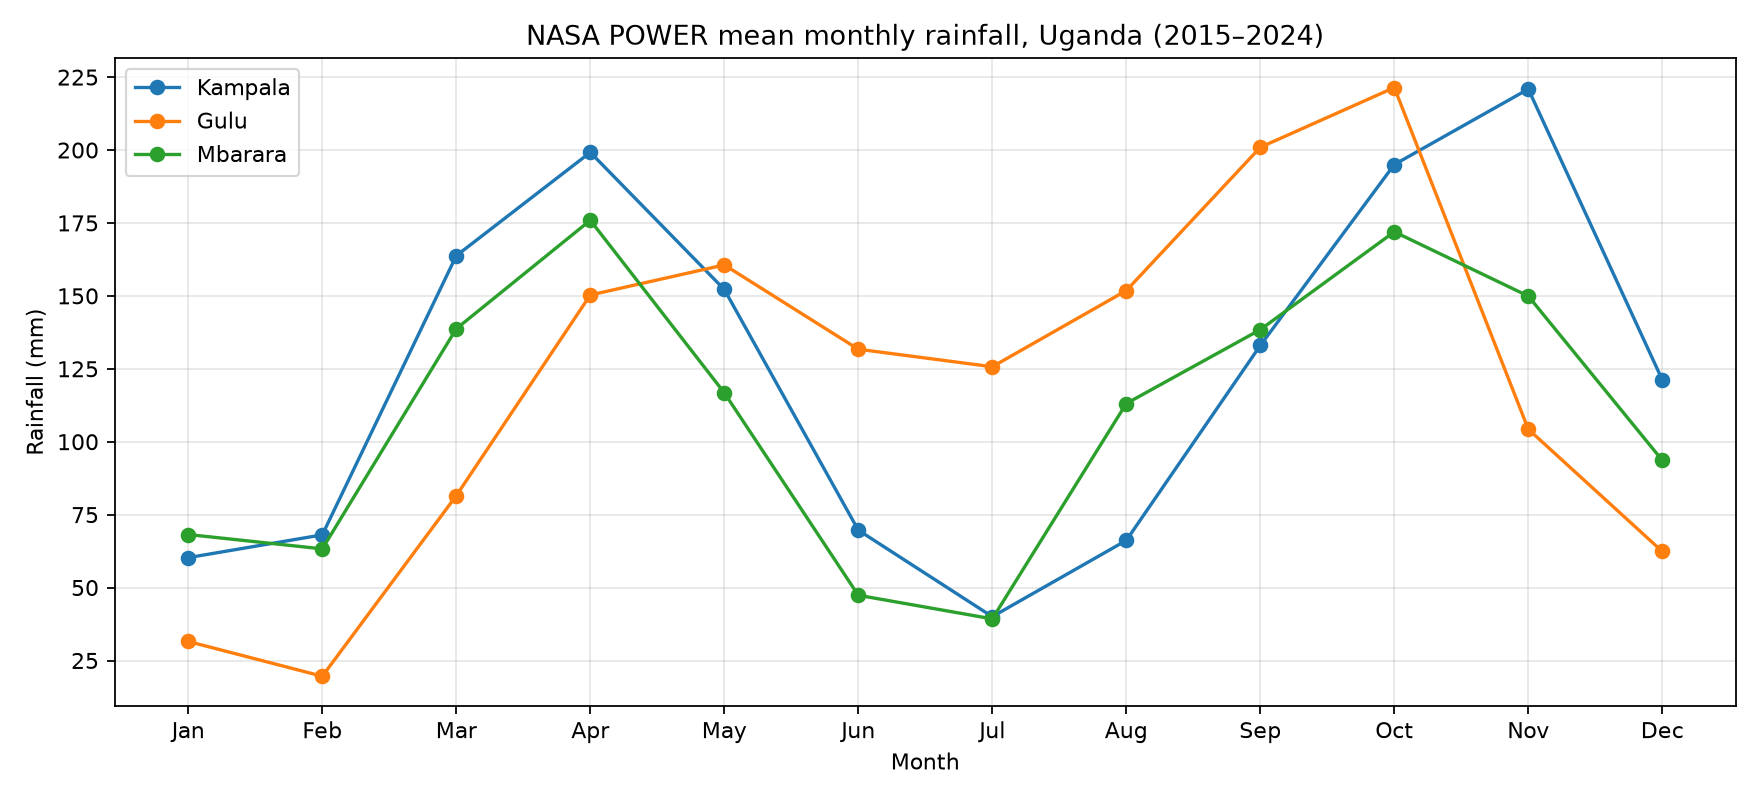

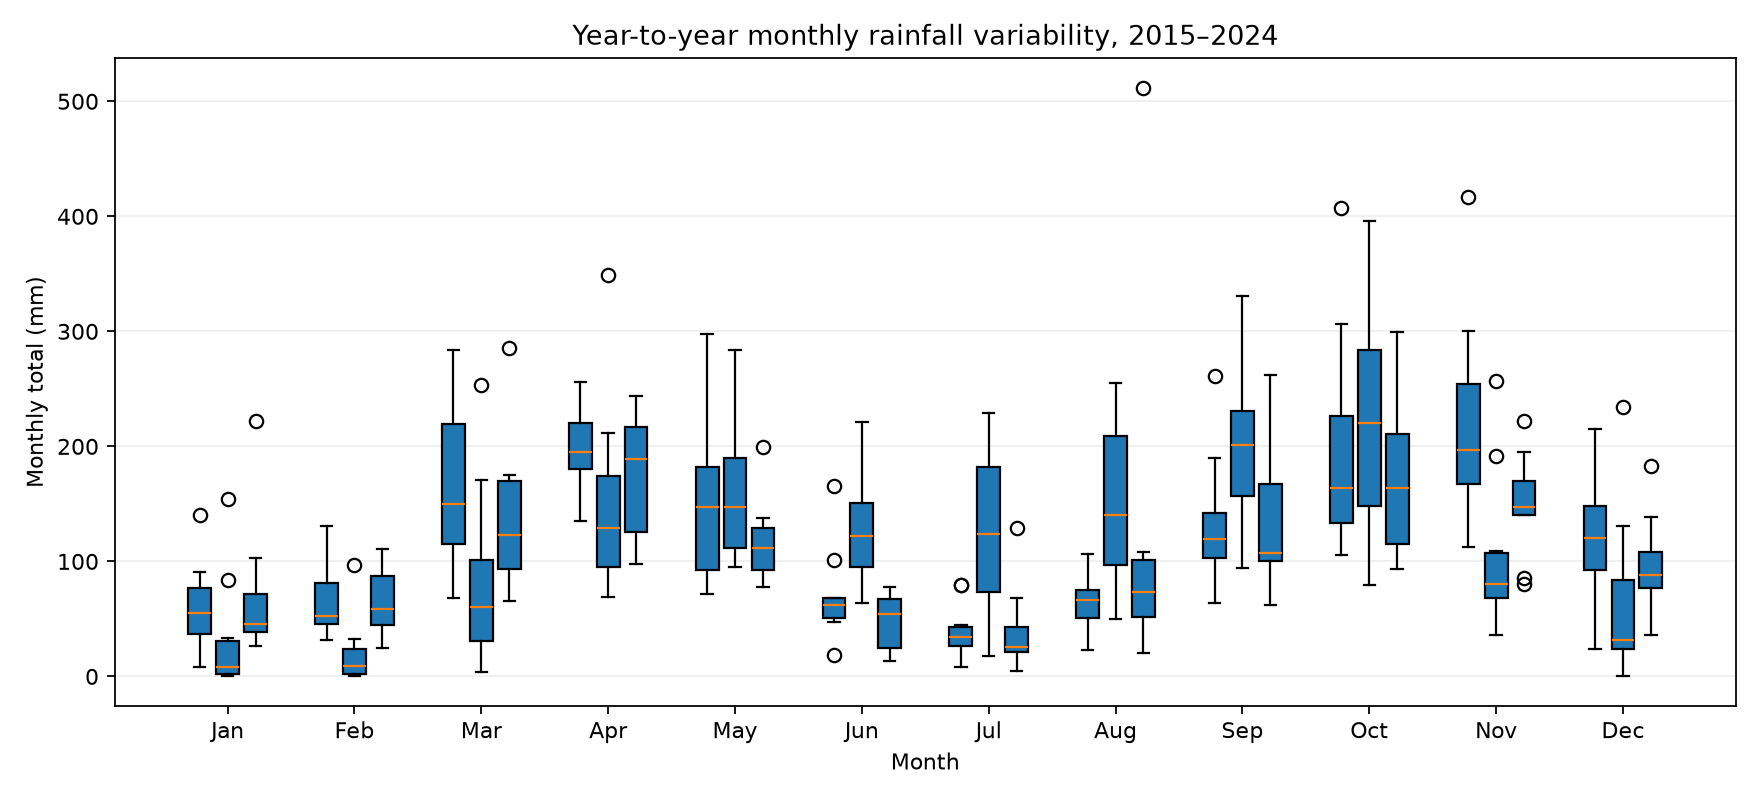

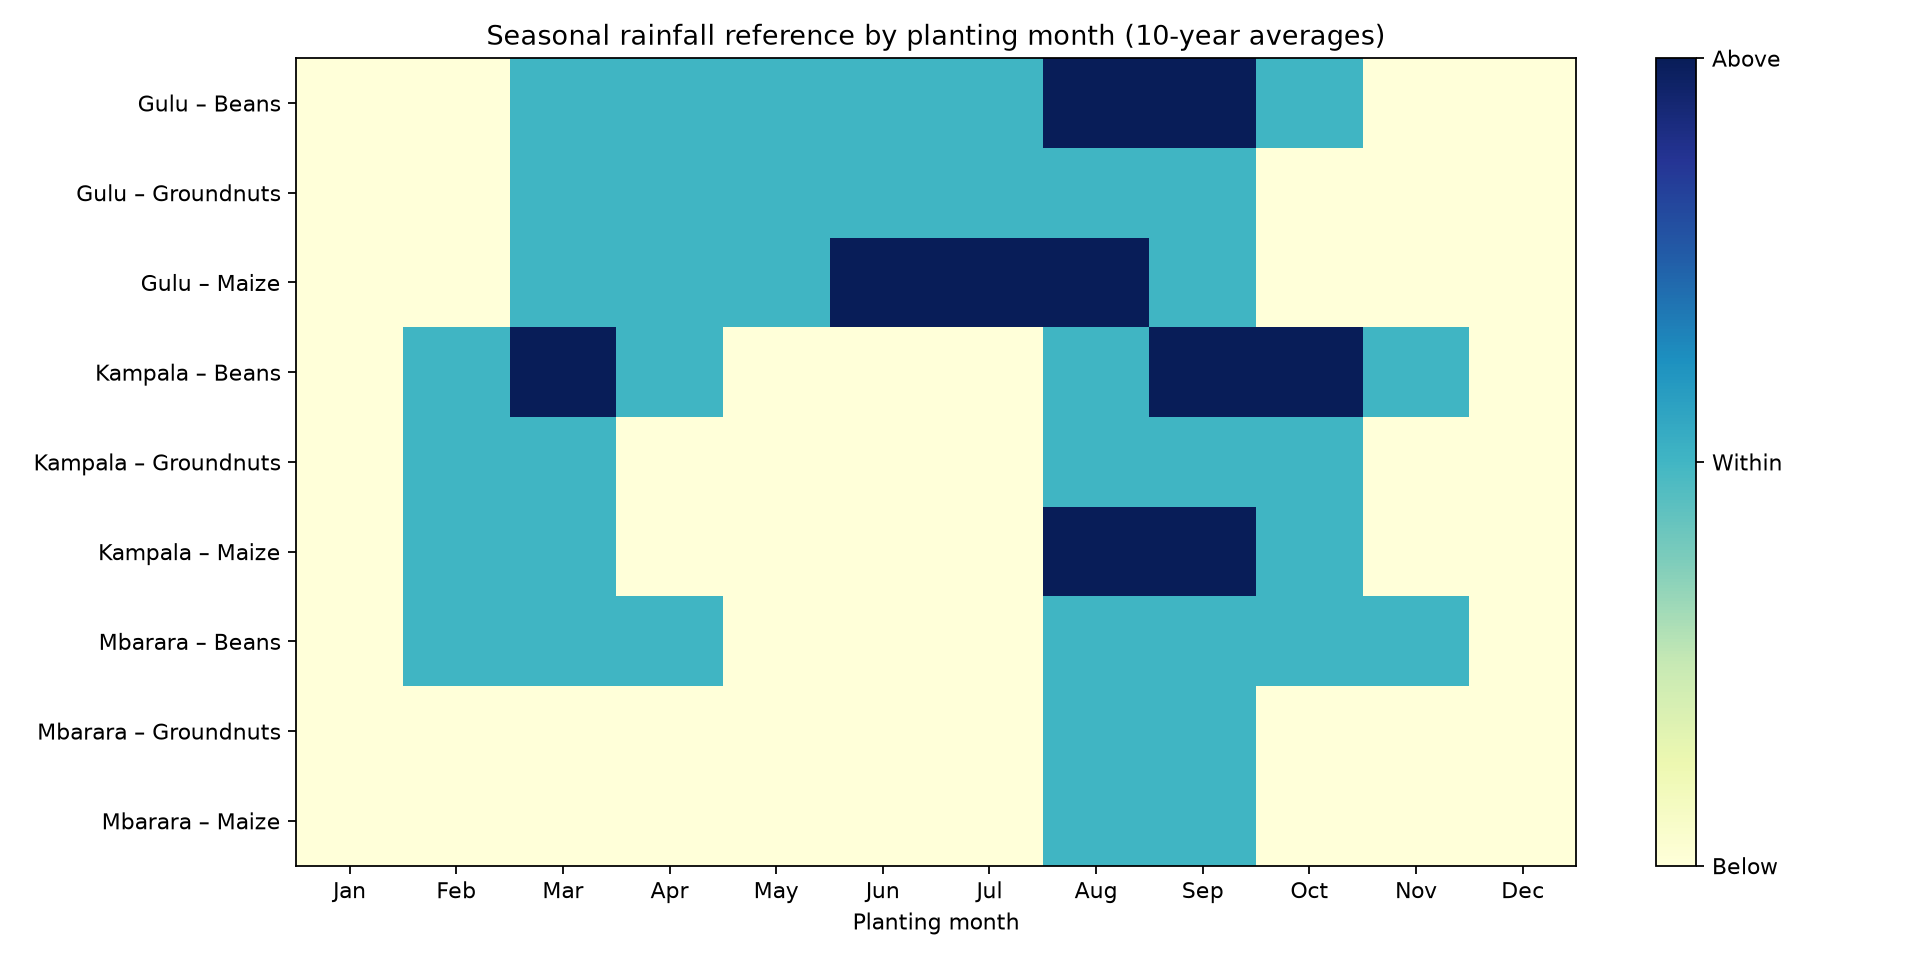

In [7]:
from IPython.display import Image, display
for name in ['rainfall_lines.png','rainfall_boxplots.png','crop_heatmap.png']:
    display(Image(filename=str(ROOT/'figures'/name)))

### Farmer Advisory for Mbarara District

In Mbarara, farmers normally depend on two rainy seasons, March to May and September to November. These are generally the best periods to grow crops such as maize, beans and groundnuts.

For beans, planting can start around March or September, once the rains have become steady. Maize can also be planted around the same time, but farmers need to choose varieties that will mature before the rains end. Groundnuts are another option, especially in areas with well-drained soils.

One thing farmers need to be careful about is planting immediately after the first rain. Sometimes it rains for a few days and then stops for weeks, which can affect seed germination and crop growth. It is better to wait until the rains are more consistent.

The rainfall data gives us an idea of what normally happens in Mbarara, but every season is different. Farmers should also consider the type of soil they have, the seeds they are planting and the seasonal weather forecasts. It is also important to seek advice from local agricultural extension officers before planting.

## References

- Uganda MAAIF, Maize Training Manual for Extension Workers: https://agriculture.go.ug/wp-content/uploads/2023/06/Maize-training-manual-for-extension-workers-in-Uganda_Reduced.pdf
- Uganda MAAIF, Beans Training Manual: https://www.agriculture.go.ug/wp-content/uploads/2023/06/Beans-training-manual-for-extension-workers-in-Uganda_Reduced-1.pdf
- FAO, Crop Water Needs: https://www.fao.org/4/S2022E/s2022e07.htm
- NASA POWER daily API: https://power.larc.nasa.gov/docs/services/api/temporal/daily/
